# Lab01 - sprint 1

Команда 13 (КТвД). ISU: 501564, 501235, 458829.

Тема: болиды. Данные из каталога NASA JPL.

Мы выбрали общую тему космоса, потому что космос красивый и там есть множество различных случайных величин. Нельзя предсказать где и когда пролетит очередной метеор. Болид это очень яркий метеор, космический камень влетает в атмосферу и ярко взрывается. Данные, как указано выше, мы берем из открытого каталога NASA. Будем смотреть три величины: сколько дней проходит между соседними болидами, сколько болидов случается за месяц и на какой широте они падают.

In [1]:
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

In [2]:
# временный стиль графиков, потом заменим на общий
C_DATA = "tab:blue"
C_THEORY = "tab:red"
C_ACCENT = "tab:orange"
C_MUTED = "gray"
plt.rcParams.update({"figure.figsize": (8, 4.5), "axes.grid": True})

## Dataset

Откуда данные и что про них пишет NASA:

- страница каталога: https://cneos.jpl.nasa.gov/fireballs/intro.html
- описание полей: https://ssd-api.jpl.nasa.gov/doc/fireball.html

На странице каталога сказано, что вспышки записывают датчики правительства США (U.S. Government sensors) и что список неполный: "This website is not meant to be a complete list of all fireball events. Only the brightest fireballs are noted."

### Загрузка

In [3]:
# каталог болидов NASA JPL, регистрация не нужна
# дату конца фиксируем, чтобы числа в работе не менялись когда в каталог добавят новые болиды
URL = "https://ssd-api.jpl.nasa.gov/fireball.api?date-max=2026-10-31"

answer = requests.get(URL).json()
raw = pd.DataFrame(answer["data"], columns=answer["fields"])
print(raw.shape)
raw.head()

(1074, 9)


,date,energy,impact-e,lat,lat-dir,lon,lon-dir,alt,vel
0,2026-10-04 03:14:45,5.4,0.18,41.8,S,173.1,W,26.9,13.8
1,2026-09-15 11:26:13,2.2,0.079,37.6,S,161.6,W,37.0,NaN
2,2026-09-11 10:18:03,6.1,0.2,0.2,S,129.6,W,70.0,NaN
3,2026-09-11 01:12:11,24.6,0.67,54.4,N,100.1,W,38.0,20.7
4,2026-09-10 05:22:22,11.1,0.33,19.3,S,28.1,W,33.6,19.3


Столбцы (по описанию полей NASA):

- `date` дата и время максимальной яркости вспышки (GMT)
- `energy` излученная энергия, $10^{10}$ Дж
- `impact-e` полная энергия взрыва, килотонны в тротиловом эквиваленте
- `lat`, `lat-dir` широта и полушарие (N или S)
- `lon`, `lon-dir` долгота и полушарие (E или W)
- `alt` высота в момент максимальной яркости, км
- `vel` скорость в момент максимальной яркости, км/с

В первых строках уже видно `NaN` в столбце `vel`, это пропуск: значение неизвестно.

In [4]:
# в каком виде пришли значения
raw.dtypes

date        str
energy      str
impact-e    str
lat         str
lat-dir     str
lon         str
lon-dir     str
alt         str
vel         str
dtype: object

In [5]:
# все столбцы пришли текстом, переводим в числа и дату
df = pd.DataFrame()
df["date"] = pd.to_datetime(raw["date"])
df["energy_kt"] = pd.to_numeric(raw["impact-e"])
df["alt_km"] = pd.to_numeric(raw["alt"])
df["vel_kms"] = pd.to_numeric(raw["vel"])

# широта со знаком: северная плюс, южная минус
lat = pd.to_numeric(raw["lat"])
df["lat"] = np.where(raw["lat-dir"] == "S", -lat, lat)

df = df.sort_values("date").reset_index(drop=True)
df.head()

,date,energy_kt,alt_km,vel_kms,lat
0,1988-04-15 03:03:10,14.000,NaN,NaN,-4.1
1,1990-10-01 03:51:47,5.200,NaN,NaN,7.5
2,1991-10-04 09:22:47,1.400,NaN,NaN,78.7
3,1993-10-31 03:39:27,0.130,NaN,NaN,51.3
4,1993-11-29 17:48:41,0.092,NaN,NaN,26.5


In [6]:
# сколько болидов в каталоге и за какой период
print("болидов в каталоге:", len(df))
print("первая запись:", df["date"].min())
print("последняя запись:", df["date"].max())

болидов в каталоге: 1074
первая запись: 1988-04-15 03:03:10
последняя запись: 2026-10-04 03:14:45


In [7]:
# сколько значений заполнено и сколько пропущено в каждом столбце
missing = pd.DataFrame({
    "заполнено": df.notna().sum(),
    "пропусков": df.isna().sum(),
    "пропусков, %": (df.isna().mean() * 100).round(1),
})
missing

,заполнено,пропусков,"пропусков, %"
date,1074,0,0.0
energy_kt,1074,0,0.0
alt_km,602,472,43.9
vel_kms,363,711,66.2
lat,888,186,17.3


В нашем каталоге 1074 болида, первый в 1988 году, последний в 2026. Для каждого есть дата и энергия взрыва болида. Есть и другие столбцы. Однако: широта неизвестна у 186 болидов (17%), высота у 472 (44%), а скорость у 711(66%). Поэтому мы не используем скорость. Интервалы между болидами считаются по датам, поэтому всё ок. А для широты остаётся 888 болидов.

### За какие годы брать данные

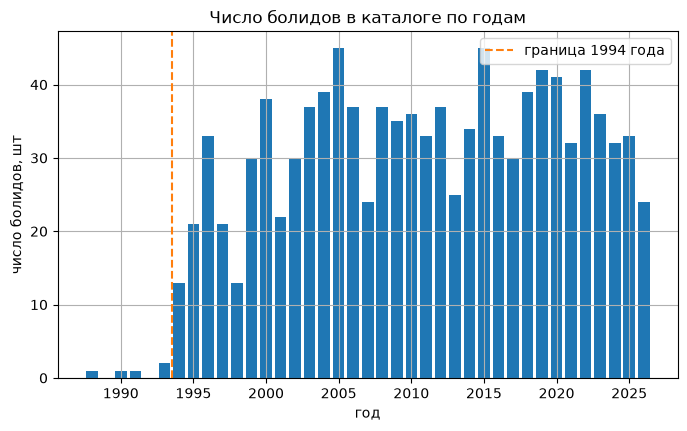

In [8]:
# число болидов в каталоге по годам
per_year = df["date"].dt.year.value_counts().sort_index()

plt.bar(per_year.index, per_year.values, color=C_DATA)
plt.axvline(1993.5, color=C_ACCENT, linestyle="--", label="граница 1994 года")
plt.title("Число болидов в каталоге по годам")
plt.xlabel("год")
plt.ylabel("число болидов, шт")
plt.legend()
plt.show()

In [9]:
# те же числа таблицей: первые годы каталога
print(per_year.head(8))

# и разброс по полным годам с 1994 по 2025
full_years = per_year.loc[1994:2025]
print("с 1994 по 2025 в год: от", full_years.min(), "до", full_years.max(), "болидов")

date
1988     1
1990     1
1991     1
1993     2
1994    13
1995    21
1996    33
1997    21
Name: count, dtype: int64
с 1994 по 2025 в год: от 13 до 45 болидов


На графике видно, что до 1994 каталог практически пуст. А вот с 1994 у нас каждый год от 13 до 45 болидов. Скорее всего в первые годы вспышки просто плохо записывали, NASA сама указывает, что список неполный. Если бы мы оставили годы до 1994 то промежутки там будут аномально большими. Поэтому мы берем данные с 1994 года.

In [10]:
# оставляем болиды с 1994 года
df = df[df["date"] >= "1994-01-01"].reset_index(drop=True)
print("болидов осталось:", len(df))
print("период:", df["date"].min(), "-", df["date"].max())

болидов осталось: 1069
период: 1994-02-01 22:38:09 - 2026-10-04 03:14:45


## Random Variable 01 (интервал между соседними болидами, дни)

### Description

### EDA & Distribution

### Independence & Estimations

## Random Variable 02 (число болидов за месяц)

### Description

### EDA & Distribution

### Independence & Estimations

## Random Variable 03 (широта точки падения)

### Description

### EDA & Distribution

### Independence & Estimations

## Lab resume

### cat_mark_table

| cat_id | notebook_link | coeff | comment |
|--------|---------------|-------|---------|
|        |               |       |         |

# Lab01 - sprint 2

## random 01

### Description

### math desc

### code

### tests

### resume

## Lab resume

### cat_mark_table

| cat_id | notebook_link | coeff | comment |
|--------|---------------|-------|---------|
|        |               |       |         |